<a href="https://colab.research.google.com/github/macbla12/MUP/blob/main/Heston.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model i metoda

Po zmianie zmiennych $x=\ln S$, $\tau=T-t$ równanie wyceny ma postać:

$$
V_\tau=
\underbrace{\tfrac12vV_{xx}+\rho\xi vV_{xv}+\tfrac12\xi^2vV_{vv}}_{\text{dyfuzja}}
+\underbrace{\left(r-\tfrac v2\right)V_x+\kappa(\theta-v)V_v}_{\text{adwekcja}}
\;\underbrace{-\,rV}_{\text{dyskonto}}
$$

Adwekcję rozwiązano metodą MPDATA, dyfuzję (z pochodną mieszaną) różnicami centralnymi, a całość połączono rozdzieleniem operatora typu Stranga.

**Parametry:**

| $K$ | $T$ | $r$ | $\kappa$ | $\theta$ | $\xi$ | $\rho$ |
|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| 100 | 1 | 0,05 | 2,0 | 0,04 | 0,3 | −0,7 |

Siatka: $100\times60$ komórek, $S\in[20,300]$, $v\in[0;0{,}5]$, $N_t=1200$.

In [2]:
!pip install -q pympdata
import os
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"

%config InlineBackend.figure_format = 'svg'

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from PyMPDATA import ScalarField, VectorField, Solver, Stepper, Options
from PyMPDATA.boundary_conditions import Extrapolated

plt.rcParams.update({
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 8,
})

In [3]:
class HestonIntegrator:
    def __init__(self, *, K=100., T=1., r=.05, kappa=2., theta=.04,
                 xi=.3, rho=-.7, nx=100, nv=60, nt=1200,
                 S_min=20., S_max=300., v_max=.5, options=None):
        self.K, self.T, self.r = K, T, r
        self.kappa, self.theta, self.xi, self.rho = kappa, theta, xi, rho
        self.nx, self.nv, self.nt = nx, nv, nt
        self.dt = T / nt

        self.x_edges = np.linspace(np.log(S_min), np.log(S_max), nx + 1)
        self.v_edges = np.linspace(0., v_max, nv + 1)
        self.dx = self.x_edges[1] - self.x_edges[0]
        self.dv = self.v_edges[1] - self.v_edges[0]
        self.x = (self.x_edges[:-1] + self.x_edges[1:]) / 2
        self.v = (self.v_edges[:-1] + self.v_edges[1:]) / 2
        self.S = np.exp(self.x)

        initial = np.maximum(self.S[:, None] - K, 0.)
        initial = np.broadcast_to(initial, (nx, nv)).copy()

        options = options or Options(n_iters=2, nonoscillatory=True,
                                    infinite_gauge=True)
        bc = (Extrapolated(), Extrapolated())
        halo = options.n_halo

        courant_x = np.broadcast_to(
            (self.v[None, :] / 2 - r) * self.dt / self.dx,
            (nx + 1, nv)
        ).copy()
        courant_v = np.broadcast_to(
            kappa * (self.v_edges[None, :] - theta) * self.dt / self.dv,
            (nx, nv + 1)
        ).copy()

        if np.max(np.abs(courant_x)) > 1 or np.max(np.abs(courant_v)) > 1:
            raise ValueError("Warunek CFL MPDATA nie jest spełniony.")

        stepper = Stepper(options=options, grid=(nx, nv))
        advectee = ScalarField(initial, halo, bc)
        advector = VectorField((courant_x, courant_v), halo, bc)
        self.solver = Solver(stepper, advectee, advector)

        v_eff = min(v_max, max(theta, 0.15))
        a, c = .5 * v_eff, .5 * xi**2 * v_eff
        d = abs(rho * xi * v_eff)
        bound = 4*a/self.dx**2 + 4*c/self.dv**2 + d/(self.dx*self.dv)
        self.dt_diff = np.inf if bound == 0 else 1.8 / bound
        self._boundaries(0.)

    def get(self):
        return self.solver.advectee.get()

    def _boundaries(self, tau):
        q = self.get()
        q[:, 0] = q[:, 1]
        q[:, -1] = q[:, -2]
        q[0, :] = 0.
        q[-1, :] = self.S[-1] - self.K * np.exp(-self.r * tau)

    def _diffusion(self, q):
        p = np.pad(q, ((1, 1), (1, 1)), mode="edge")
        dxx = (p[2:, 1:-1] - 2*q + p[:-2, 1:-1]) / self.dx**2
        dvv = (p[1:-1, 2:] - 2*q + p[1:-1, :-2]) / self.dv**2
        dxv = (p[2:, 2:] - p[2:, :-2] - p[:-2, 2:] + p[:-2, :-2]) / (4*self.dx*self.dv)
        v = self.v[None, :]
        return .5*v*dxx + self.rho*self.xi*v*dxv + .5*self.xi**2*v*dvv

    def _diffusion_step(self, interval, tau):
        n = max(1, int(np.ceil(interval / self.dt_diff)))
        h = interval / n
        for _ in range(n):
            q = self.get()
            q += h * self._diffusion(q)
            self._boundaries(tau)

    def __call__(self, *, outfreq=200):
        output, times = [self.get().copy()], [0.]
        for it in range(1, self.nt + 1):
            tau = it * self.dt
            self._diffusion_step(self.dt/2, tau)
            self.get()[:] *= np.exp((self.kappa - self.r) * self.dt/2)
            self._boundaries(tau)
            self.solver.advance(n_steps=1)
            self._boundaries(tau)
            self.get()[:] *= np.exp((self.kappa - self.r) * self.dt/2)
            self._boundaries(tau)
            self._diffusion_step(self.dt/2, tau)
            self._boundaries(tau)
            if it % outfreq == 0 or it == self.nt:
                output.append(self.get().copy())
                times.append(tau)
        result = np.asarray(output[-1])
        if not np.isfinite(result).all():
            raise FloatingPointError(
                "Solver zwrócił NaN/Inf. Nie można raportować wiarygodnych metryk."
            )
        return np.asarray(times), output

def solve_heston(**kwargs):
    integrator = HestonIntegrator(**kwargs)
    times, output = integrator(outfreq=max(1, integrator.nt // 4))
    return integrator, times, output

def bs_analytic(S, K, T, r, sigma):
    d1 = (np.log(S/K) + (r + .5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

params = dict(K=100., T=1., r=.05, kappa=2., theta=.04,
              xi=.3, rho=-.7, nx=100, nv=60, nt=1200,
              S_min=20., S_max=300., v_max=.5)
integrator, times, output = solve_heston(**params)
V = output[-1]

# Wyniki

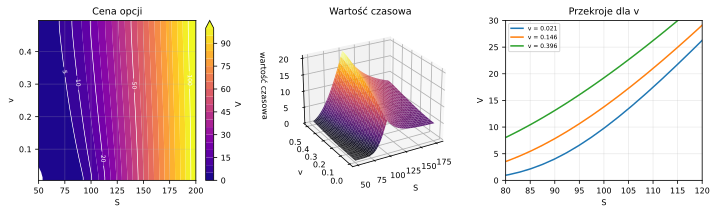

In [6]:
intrinsic = np.maximum(integrator.S[:, None] - integrator.K, 0.)

mask_S = (integrator.S >= 50) & (integrator.S <= 180)
S_mesh, v_mesh = np.meshgrid(integrator.S[mask_S], integrator.v)
V_mesh = V[mask_S, :].T
time_mesh = V_mesh - np.maximum(S_mesh - integrator.K, 0.)

fig = plt.figure(figsize=(10, 3))

ax = fig.add_subplot(1, 3, 1)
im = ax.contourf(integrator.S, integrator.v, V.T,
                 levels=np.linspace(0, 100, 21), cmap="plasma", extend="max")
cs = ax.contour(integrator.S, integrator.v, V.T,
                levels=[5, 10, 20, 50, 100], colors="white", linewidths=.6)
ax.clabel(cs, inline=True, fontsize=6, fmt="%.0f")
fig.colorbar(im, ax=ax, label="V")
ax.set(xlim=(50, 200), xlabel="S", ylabel="v", title="Cena opcji")

ax = fig.add_subplot(1, 3, 2, projection="3d")
surf = ax.plot_surface(S_mesh, v_mesh, time_mesh, cmap="inferno",
                       edgecolor="none", alpha=.9)
ax.set(xlabel="S", ylabel="v", zlabel="wartość czasowa",
       title="Wartość czasowa")
ax.view_init(elev=25, azim=-120)

ax = fig.add_subplot(1, 3, 3)
for target_v in [0.02, 0.15, 0.40]:
    jv = np.argmin(np.abs(integrator.v - target_v))
    ax.plot(integrator.S, V[:, jv], label=f"v = {integrator.v[jv]:.3f}")
ax.set(xlim=(80, 120), ylim=(0, 30), xlabel="S", ylabel="V",
       title="Przekroje dla v")
ax.legend(fontsize=6)

fig.tight_layout()
plt.show()

Cena opcji rośnie z $S$ i z $v$: im większa wariancja, tym większa szansa na silny ruch ceny w górę, a ponieważ strata jest ograniczona do premii, opcja jest wtedy droższa. Wartość czasowa jest największa w pobliżu ceny wykonania ($S\approx K$), gdzie niepewność co do wygaśnięcia „w pieniądzu" jest największa, a dla $S\ll K$ i $S\gg K$ maleje do zera. Przekroje pokazują ten sam efekt: krzywe dla większego $v$ leżą wyżej, a różnice między nimi są największe wokół $K$.

# Weryfikacja: granica Blacka–Scholesa

Dla $\xi=0$, $\rho=0$ i $v=\theta$ wynik porównano z wzorem analitycznym Blacka–Scholesa ($\sigma=\sqrt\theta$). Ponieważ $\theta$ nie leży w węźle siatki, użyto interpolacji liniowej po $v$.

In [7]:
limit_params = params.copy()
limit_params.update(xi=0., rho=0.)
limit_solver, _, limit_output = solve_heston(**limit_params)
V_limit = limit_output[-1]

sigma_bs = np.sqrt(limit_params["theta"])
bs = bs_analytic(limit_solver.S, limit_params["K"], limit_params["T"],
                 limit_params["r"], sigma_bs)

V_theta = np.array([
    np.interp(limit_params["theta"], limit_solver.v, V_limit[i, :])
    for i in range(len(limit_solver.S))
])

mask = (limit_solver.S >= 50) & (limit_solver.S <= 180)
S_rep = limit_solver.S[mask]
heston_rep, bs_rep = V_theta[mask], bs[mask]
abs_diff = np.abs(heston_rep - bs_rep)
max_err = float(np.max(abs_diff))
rmse = float(np.sqrt(np.mean(abs_diff**2)))

if not (np.isfinite(max_err) and np.isfinite(rmse)):
    raise FloatingPointError("Metryki porównania Heston–Black–Scholes są niefinitywne.")

print(f"Maksymalny błąd bezwzględny: {max_err:.6f}")
print(f"RMSE: {rmse:.6f}")

Maksymalny błąd bezwzględny: 0.130101
RMSE: 0.051382


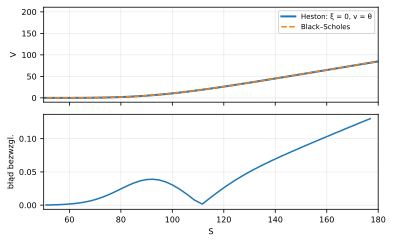

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5.5, 3.4), sharex=True)
ax1.plot(limit_solver.S, V_theta, label="Heston: ξ = 0, v = θ", linewidth=2)
ax1.plot(limit_solver.S, bs, "--", label="Black–Scholes")
ax1.set(xlim=(50, 180), ylabel="V")
ax1.legend(fontsize=7)
ax2.plot(S_rep, abs_diff)
ax2.set(xlabel="S", ylabel="błąd bezwzgl.")
fig.tight_layout()
fig.tight_layout()
plt.show()

Błąd jest mały (maksymalnie ok. 0,13 przy cenie opcji rzędu 85, czyli poniżej 0,2%), ale ma wyraźny kształt, który nie wygląda na szum. Poniższe wyjaśnienie jest najbardziej prawdopodobne:

- Górka w okolicy $S\approx 90$–$100$ - wypłata $\max(S-K,0)$ ma załamanie w $K$, którego siatka nie rozwiązuje dokładnie, a schemat (MPDATA z dodatkowymi poprawkami i dyfuzją numeryczną) lekko je wygładza. Błędy dyskretyzacji koncentrują się więc tam, gdzie rozwiązanie jest najmniej gładkie.
- Spadek do zera w okolicy $S\approx 112$ - to miejsce, w którym błąd zmienia znak (wykres pokazuje wartość bezwzględną, stąd „szpic").
- Wzrost błędu dla dużych $S$ - siatka jest równomierna w $\ln S$, więc krok w samej cenie $\Delta S\approx S\,\Delta x$ rośnie wraz z $S$, a wartość opcji rośnie niemal liniowo. Błąd bezwzględny rośnie więc mniej więcej proporcjonalnie do $S$, przy niemal stałym błędzie względnym.
- Dodatkowo drobny wkład daje interpolacja liniowa po $v$ (bo $\theta$ nie jest węzłem) oraz warunek brzegowy na $S_{\max}$.

# Wnioski

1. Cena opcji zależy od dwóch zmiennych stanu $S$ i $v$ a wyższa wariancja podnosi wartość czasową, szczególnie w pobliżu ceny wykonania.
2. W granicy $\xi=0$ solver odtwarza wzór Blacka–Scholesa z niewielkim błędem, co potwierdza poprawność implementacji.
3. Dokładność zależy od rozdzielczości siatki i błędów schematu numerycznego.